# Logistic regression for binary classification using Gradient Descent algorithm

<b>Logistic Regression model</b>  is used to model the probability of a certain class or event existing such as pass/fail, win/lose, alive/dead or healthy/sick.

A <b>binary logistic model</b> has a dependent variable with two possible values, such as pass/fail which is represented by labels 1/0.

<div align="right">   Reference: Wikipedia </div>


In <b>logistic classification</b>, the classification is based on the hypothesis $ h_\theta(x) $:

If $ h_\theta(x) \geq 0.5 $ predict $ y = 1 $.

If $ h_\theta(x) < 0.5 $ predict $ y = 0 $.

In other words,  $ 0 \leq h_\theta(x) \leq 1 $.
    

The model uses the <b>hypothesis</b> $$ h = h_\theta(x) = g(\theta^T x) $$
    
The <b>Sigmoid function</b> $ g $ is defined as $$ g(z) = \frac{1}{1+e^{-z}} $$

To compute the parameters $\theta$ use the <b>Cost function</b>:
$$ J(\theta) = \frac{1}{m} \big( -y^T log(h) - (1-y)^T log (1-h) \big) $$
and minimize the cost function over $\theta$ using Gradient Descent algorithm.


<b>Gradient descent algorithm</b> is given as

repeat until convergence {
\begin{align*}
    \theta_1 &= \theta_1 - \alpha \frac{1}{m}\sum_{i=1}^{m} \big ( h_\theta (x^{(i)}) - y^{(i)} \big ) * x^{(i)} \\
    \theta_0 &= \theta_0 - \alpha \frac{1}{m}\sum_{i=1}^{m} \big ( h_\theta (x^{(i)}) - y^{(i)} \big )
\end{align*}
}

<div align="right"> Reference: Coursera course on Machine Learning by Andrew Ng </div>

## 1. Import the libraries

In [1]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Import and visualize the dataset

In [2]:
# Import the dataset

df = pd.read_csv('./Admission.csv')
# change the path as necessary
# Reference dataset taken from Coursera course on Machine Learning by Andrew Ng
df.columns = df.columns.str.strip()   # the header has a trailing space ('Exam2 ')
print(df.head())

       Exam1      Exam2  Admitted
0  34.623660  78.024693         0
1  30.286711  43.894998         0
2  35.847409  72.902198         0
3  60.182599  86.308552         1
4  79.032736  75.344376         1


In [3]:
# X = first two columns; Exam 1 and Exam 2
X = df.iloc[:, :-1]

# y = target values, last column
Y = df.iloc[:, -1]

# filter out the applicants that got admitted
admitted = df.loc[Y == 1]

# filter out the applicants that did not get admitted
not_admitted = df.loc[Y == 0]


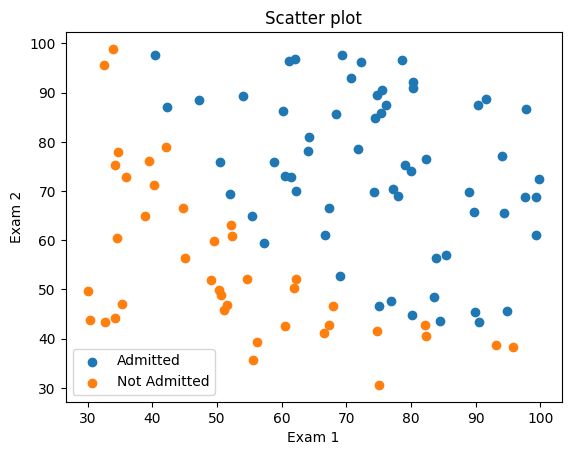

In [4]:
# Visualize
plt.scatter(admitted.iloc[:, 0], admitted.iloc[:, 1], label='Admitted')
plt.scatter(not_admitted.iloc[:, 0], not_admitted.iloc[:, 1],  label='Not Admitted')
plt.legend()
plt.title('Scatter plot')
plt.xlabel('Exam 1')
plt.ylabel('Exam 2')
plt.show()

## 3. Preprocessing the data

In [5]:
from sklearn import preprocessing
from sklearn.model_selection import train_test_split

# make y a column vector (numpy array)
Y = Y.values.reshape(-1, 1)

# split FIRST, then scale: the scaler must only learn min/max from the training data
X_train, X_test, Y_train, Y_test = train_test_split(X.values, Y, test_size=0.2, random_state=42, stratify=Y)

# Min max scaler transforms features by scaling each feature to a given range, default is (0,1).
# The transformation is given by:
# X_std = (X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
min_max_scaler = preprocessing.MinMaxScaler()
X_train = min_max_scaler.fit_transform(X_train)   # fit on train only
X_test = min_max_scaler.transform(X_test)         # re-use the train min/max

# add bias = 1 at column 0  (so that theta0 is the intercept)
X_train = np.c_[np.ones((X_train.shape[0], 1)), X_train]
X_test = np.c_[np.ones((X_test.shape[0], 1)), X_test]
print('Size of X_train', X_train.shape, ' X_test', X_test.shape)
print('Size of Y_train', Y_train.shape, ' Y_test', Y_test.shape)

Size of X_train (80, 3)  X_test (20, 3)
Size of Y_train (80, 1)  Y_test (20, 1)


## 4. Define relevant functions

#### Sigmoid function $$ g(z) = \frac{1}{1+e^{-z}} $$

#### Hypothesis $$ h_\theta (x) = g ( \theta^T x ) $$

#### Cost function
$$ J(\theta) = \frac{1}{m} \big( -y^T log(h) - (1-y)^T log (1-h) \big) $$
where $ h = g ( \theta^T x ) $


In [6]:
def sigmoid(a):
    return 1.0 / (1 + np.exp(-a))

def cost(x, y, theta):
    m = x.shape[0]
    h = sigmoid(np.matmul(x, theta))
    cost = (np.matmul(-y.T, np.log(h)) - np.matmul((1 - y.T), np.log(1 - h))) / m
    return cost

def gradient_Descent(theta, alpha, x, y):
    m = x.shape[0]
    h = sigmoid(np.matmul(x, theta))
    grad = np.matmul(x.T, (h - y)) / m   # dJ/dtheta
    theta = theta - alpha * grad         # plain gradient step: theta := theta - alpha * grad
    return theta

## 5. Build the logistic regression model

### Using gradient descent

In [7]:
# create and initialize theta parameters. # X_train is m x 3 (bias, exam1, exam2)

Theta = np.zeros((X_train.shape[1], 1))
print('Size of Theta ' , Theta.shape)
print(Theta)

Size of Theta  (3, 1)
[[0.]
 [0.]
 [0.]]


In [8]:
n_iterations = 10000
learning_rate = 1.0  # hyperparameter - fixed by trial and error (features are scaled to [0,1], so a large step is stable)
# to store the cost values
cost_history = []
for i in range(n_iterations):
    Theta = gradient_Descent(Theta, learning_rate, X_train, Y_train)
    J_new = cost(X_train, Y_train, Theta)
    cost_history.append(J_new.flatten())
    if i % 1000 == 0:
        print('epoch = {}, cost = {}'.format(i, J_new))
print('Training completed')

epoch = 0, cost = [[0.66015295]]
epoch = 1000, cost = [[0.24611559]]
epoch = 2000, cost = [[0.23576356]]
epoch = 3000, cost = [[0.23330597]]
epoch = 4000, cost = [[0.23251444]]
epoch = 5000, cost = [[0.2322245]]
epoch = 6000, cost = [[0.23211091]]
epoch = 7000, cost = [[0.23206464]]
epoch = 8000, cost = [[0.23204534]]
epoch = 9000, cost = [[0.23203718]]
Training completed


In [9]:
print(Theta.flatten()) # theta0, theta1 theta2

[-11.73533336  13.14900131  12.64079981]


## 6. Make predicitons



In [10]:
# h(x) = g(theta.T * x)
y_pred_train = (sigmoid(np.matmul(X_train, Theta)) > .5).astype(int)
y_pred_test = (sigmoid(np.matmul(X_test, Theta)) > .5).astype(int)

## 7. Visualize

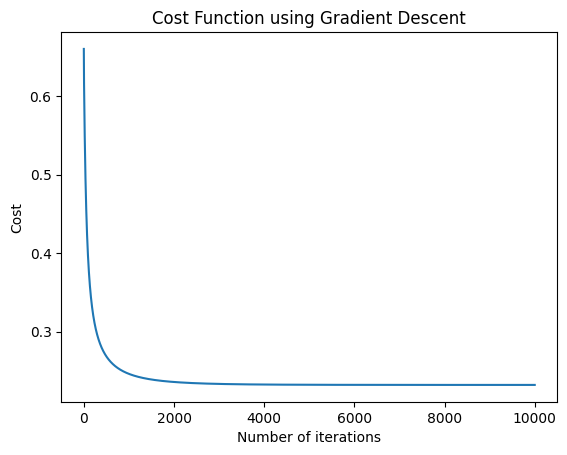

In [11]:
# plot the cost function

plt.plot(cost_history)
plt.title('Cost Function using Gradient Descent')
plt.xlabel("Number of iterations")
plt.ylabel("Cost")
plt.show()

## 8. Performance Measures

In [12]:
# Compute the accuracy on train and on the held-out test set
print('Train accuracy: %.1f %%' % (np.mean(y_pred_train == Y_train) * 100))
print('Test  accuracy: %.1f %%' % (np.mean(y_pred_test == Y_test) * 100))

Train accuracy: 88.8 %
Test  accuracy: 95.0 %


In [13]:
print(Y_test.flatten())   # actual test labels

[1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 1 1 1 1]


In [14]:
print(y_pred_test.flatten())   # predicted test labels

[1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 1 0 1 1 1]
